# Project 4B: Feature Matching for Autostitching

Following Brown, Szeliski & Winder, *Multi-Image Matching using Multi-Scale Oriented Patches* (MOPS),
with the simplifications from the assignment: single-scale Harris, axis-aligned 8x8 descriptors,
Lowe's ratio test, and 4-point RANSAC.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.ndimage import gaussian_filter
from harris import get_harris_corners, dist2

DATA, OUT = Path("data"), Path("out")
POINTS = DATA / "points"
OUT.mkdir(exist_ok=True)
MAX_SIDE = 1200  # same downscale as Part A, so the clicked points still line up

SETS = {
    "mosaic1": ["data/mosaic1_left.jpg", "data/mosaic1_mid.jpg", "data/mosaic1_right.jpg"],
    "mosaic2": ["data/mosaic2_left.jpg", "data/mosaic2_mid.jpg", "data/mosaic2_right.jpg"],
    "mosaic3": ["data/mosaic3_left.jpg", "data/mosaic3_right.jpg"],
}

## Helpers from Part A
Image I/O, homography fitting, inverse warping and the two-band mosaic blend, copied unchanged from
`partA.ipynb`.

In [4]:
def load_image(path, max_side=MAX_SIDE):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    s = max_side / max(img.size)
    if s < 1:
        img = img.resize((round(img.width * s), round(img.height * s)), Image.LANCZOS)
    return np.asarray(img, dtype=np.float64) / 255.0


def save_image(img, name):
    Image.fromarray((np.clip(img, 0, 1) * 255).round().astype(np.uint8)).save(OUT / name)


def show(imgs, titles=None, size=5, save=None):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size), squeeze=False)
    for i, (ax, im) in enumerate(zip(axes[0], imgs)):
        ax.imshow(np.clip(im, 0, 1), cmap="gray"); ax.axis("off")
        if titles: ax.set_title(titles[i])
    plt.tight_layout()
    if save: fig.savefig(OUT / save, dpi=150, bbox_inches="tight")
    plt.show()


def apply_H(H, pts):
    p = np.c_[pts, np.ones(len(pts))] @ H.T
    return p[:, :2] / p[:, 2:3]


def build_system(im1_pts, im2_pts):
    A, b = [], []
    for (x, y), (u, v) in zip(im1_pts, im2_pts):
        A.append([x, y, 1, 0, 0, 0, -u * x, -u * y]); b.append(u)
        A.append([0, 0, 0, x, y, 1, -v * x, -v * y]); b.append(v)
    return np.array(A, float), np.array(b, float)


def computeH(im1_pts, im2_pts):
    A, b = build_system(im1_pts, im2_pts)
    h = np.linalg.lstsq(A, b, rcond=None)[0]
    return np.append(h, 1).reshape(3, 3)


def warp_bbox(shape, H):
    h, w = shape[:2]
    c = apply_H(H, np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], float))
    x0, y0 = np.floor(c.min(0)).astype(int)
    x1, y1 = np.ceil(c.max(0)).astype(int)
    return x0, y0, x1 - x0 + 1, y1 - y0 + 1  # x0, y0, width, height


def inverse_map(H, bbox):
    x0, y0, W, Hgt = bbox
    if W * Hgt > 60e6:
        raise ValueError(f"output would be {W}x{Hgt}; the homography is too extreme")
    xs, ys = np.meshgrid(np.arange(x0, x0 + W), np.arange(y0, y0 + Hgt))
    src = apply_H(np.linalg.inv(H), np.c_[xs.ravel(), ys.ravel()])
    return src[:, 0].reshape(Hgt, W), src[:, 1].reshape(Hgt, W)


def bilinear_sample(im, x, y):
    h, w = im.shape[:2]
    valid = (x >= 0) & (x <= w - 1) & (y >= 0) & (y <= h - 1)
    x0 = np.clip(np.floor(x).astype(int), 0, w - 2)
    y0 = np.clip(np.floor(y).astype(int), 0, h - 2)
    ax, ay = np.clip(x - x0, 0, 1), np.clip(y - y0, 0, 1)
    if im.ndim == 3:
        ax, ay = ax[..., None], ay[..., None]
    top = im[y0, x0] * (1 - ax) + im[y0, x0 + 1] * ax
    bot = im[y0 + 1, x0] * (1 - ax) + im[y0 + 1, x0 + 1] * ax
    out = top * (1 - ay) + bot * ay
    out[~valid] = 0
    return out, valid.astype(float)


def warpImageBilinear(im, H, bbox=None):
    bbox = warp_bbox(im.shape, H) if bbox is None else bbox
    sx, sy = inverse_map(H, bbox)
    out, alpha = bilinear_sample(im, sx, sy)
    return out, alpha, bbox[:2]


def feather_alpha(h, w):
    y, x = np.mgrid[0:h, 0:w]
    d = np.minimum.reduce([x + 1, w - x, y + 1, h - y]).astype(float)
    return d / d.max()


def canvas_bbox(shapes, Hs):
    boxes = np.array([warp_bbox(s, H) for s, H in zip(shapes, Hs)])
    x0, y0 = boxes[:, 0].min(), boxes[:, 1].min()
    x1, y1 = (boxes[:, 0] + boxes[:, 2]).max(), (boxes[:, 1] + boxes[:, 3]).max()
    return x0, y0, x1 - x0, y1 - y0


def blend_two_band(imgs, weights, sigma=5):
    W = np.stack(weights)  # n, H, W
    lows, highs = [], []
    for im, w in zip(imgs, W):
        m = (w > 0).astype(float)
        low = gaussian_filter(im * m[..., None], (sigma, sigma, 0)) / \
              np.maximum(gaussian_filter(m, sigma), 1e-6)[..., None]
        lows.append(low * m[..., None]); highs.append((im - low) * m[..., None])
    total = W.sum(0)
    low = np.einsum("nhw,nhwc->hwc", W, np.stack(lows)) / np.maximum(total, 1e-12)[..., None]
    best = W.argmax(0)
    high = np.take_along_axis(np.stack(highs), best[None, ..., None], 0)[0]
    return np.clip(low + high, 0, 1) * (total > 0)[..., None]


def make_mosaic(imgs, Hs, weights=None, sigma=5):
    weights = weights or [feather_alpha(*im.shape[:2]) for im in imgs]
    bbox = canvas_bbox([im.shape for im in imgs], Hs)
    warped, ws = [], []
    for im, w, H in zip(imgs, weights, Hs):
        out, alpha, _ = warpImageBilinear(np.dstack([im, w]), H, bbox)
        warped.append(out[..., :3]); ws.append(out[..., 3] * alpha)
    return blend_two_band(warped, ws, sigma), warped, ws

### Load the images
The same three sets as Part A. The middle image of each set is the reference.

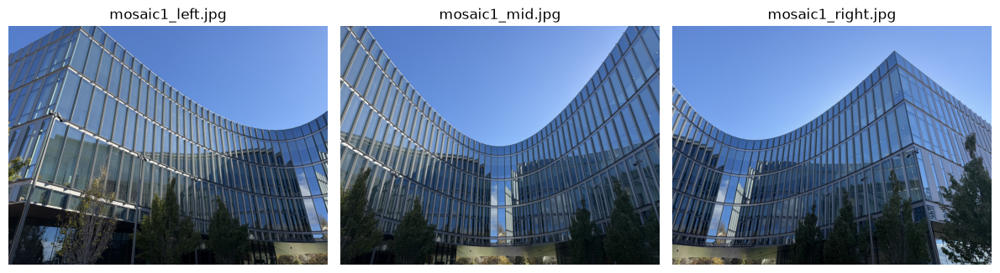

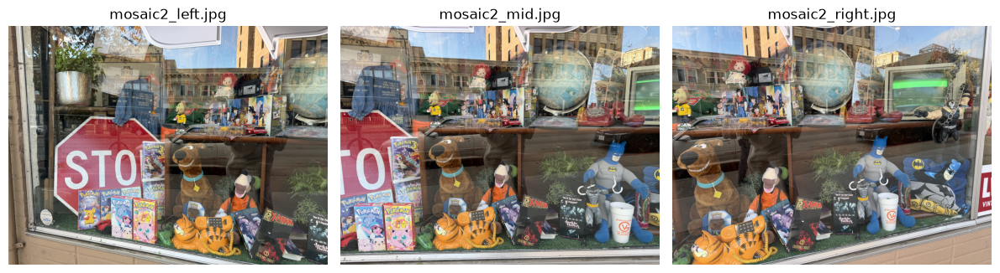

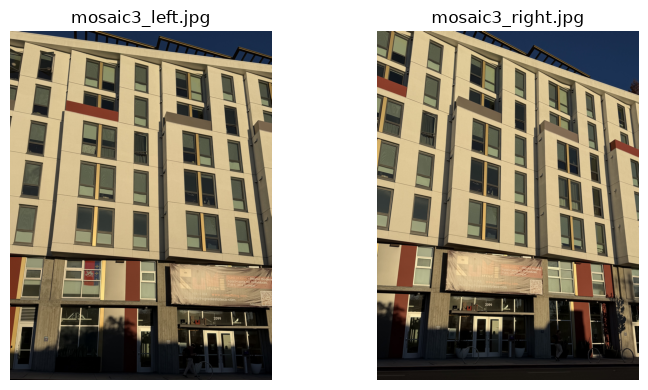

In [5]:
images = {name: [load_image(p) for p in paths] for name, paths in SETS.items()}
for name, ims in images.items():
    show(ims, [Path(p).name for p in SETS[name]], size=4)

## B.1 Harris Corner Detection

`get_harris_corners` (from the provided `harris.py`) computes the Harris response $h$ with
$\sigma = 1$ and returns every local maximum of $h$ that is more than 20 px from the border
(that margin also guarantees the 40x40 descriptor window of B.2 fits inside the image).
Like the threshold $t$ in the paper, I drop maxima whose strength is below $10^{-3}$ of the
image's strongest response; these are noise in flat regions such as sky and walls.
Points are stored as $(x, y)$ rows, the same convention as Part A.

In [7]:
def to_gray(im):
    return im @ np.array([0.299, 0.587, 0.114])


def harris_corners(im, rel_thresh=1e-3):
    h, coords = get_harris_corners(to_gray(im))
    f = h[coords[0], coords[1]]
    keep = f > rel_thresh * f.max()
    return coords[::-1].T[keep].astype(float), f[keep]  # (x, y) points, corner strengths


def plot_corners(ax, im, pts, title, size=4, color="r"):
    ax.imshow(im); ax.axis("off"); ax.set_title(title)
    ax.scatter(pts[:, 0], pts[:, 1], s=size, c=color, linewidths=0)

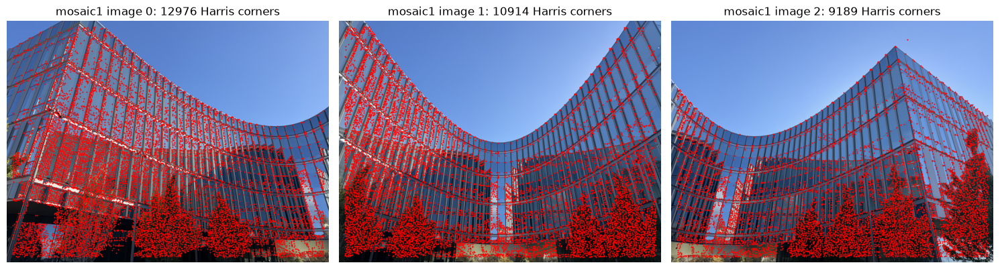

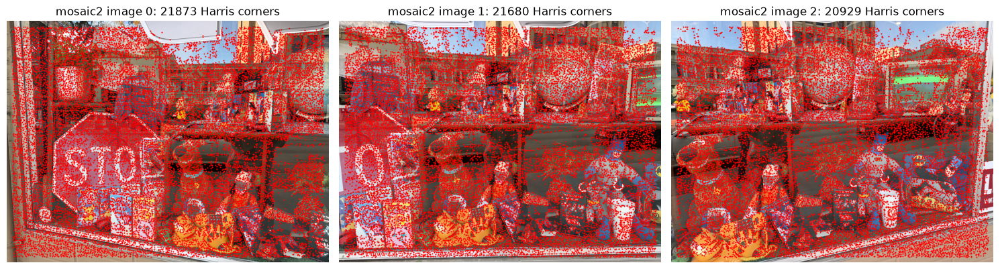

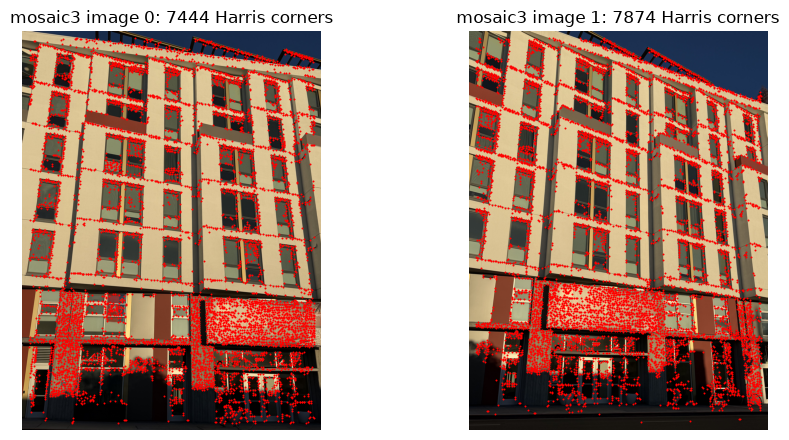

In [8]:
corners = {name: [harris_corners(im) for im in ims] for name, ims in images.items()}

for name, ims in images.items():
    fig, axes = plt.subplots(1, len(ims), figsize=(5 * len(ims), 4.5))
    for i, (ax, im, (pts, f)) in enumerate(zip(axes, ims, corners[name])):
        plot_corners(ax, im, pts, f"{name} image {i}: {len(pts)} Harris corners", size=2)
    plt.tight_layout()
    fig.savefig(OUT / f"{name}_harris.jpg", dpi=150, bbox_inches="tight"); plt.show()

### Adaptive Non-Maximal Suppression (ANMS)

In [9]:
N_IP = 500


def anms(pts, f, n_ip=N_IP, c_robust=0.9, chunk=2000):
    order = np.argsort(-f)
    pts, f = pts[order], f[order]
    r2 = np.full(len(pts), np.inf)
    for s in range(0, len(pts), chunk):
        e = min(s + chunk, len(pts))
        d = dist2(pts[s:e], pts[:e])  # only stronger corners (the prefix) can suppress
        d[f[s:e, None] >= c_robust * f[None, :e]] = np.inf
        r2[s:e] = d.min(1)
    keep = np.argsort(-r2)[:n_ip]
    return pts[keep], np.sqrt(r2[keep])

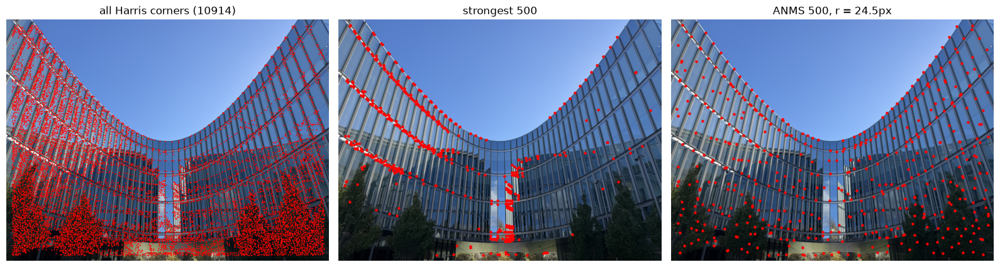

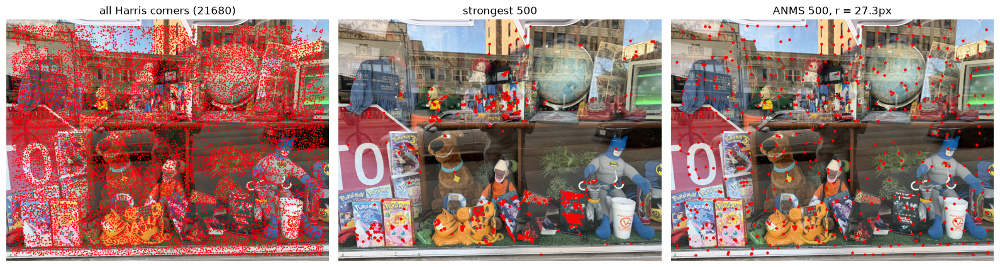

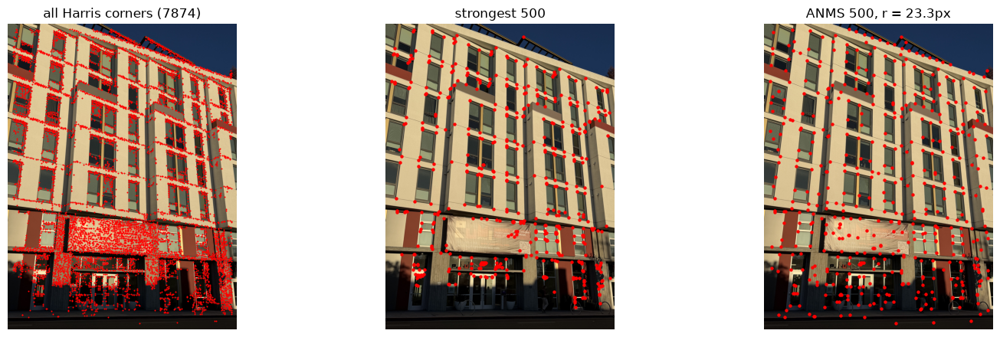

In [10]:
anms_pts = {}
for name, ims in images.items():
    results = [anms(pts, f) for pts, f in corners[name]]
    anms_pts[name] = [sel for sel, _ in results]

    ref = len(ims) // 2
    pts, f = corners[name][ref]
    sel, r = results[ref]
    strongest = pts[np.argsort(-f)[:N_IP]]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    plot_corners(axes[0], ims[ref], pts, f"all Harris corners ({len(pts)})", size=2)
    plot_corners(axes[1], ims[ref], strongest, f"strongest {N_IP}", size=10)
    plot_corners(axes[2], ims[ref], sel, f"ANMS {N_IP}, r = {r.min():.1f}px", size=10)
    plt.tight_layout()
    fig.savefig(OUT / f"{name}_anms.jpg", dpi=150, bbox_inches="tight"); plt.show()

## B.2 Feature Descriptor Extraction


In [11]:
def extract_descriptors(im, pts, window=40, size=8, sigma=2):
    g = gaussian_filter(to_gray(im), sigma)
    offs = (np.arange(size) - (size - 1) / 2) * (window / size)  # -17.5 ... 17.5
    dx, dy = np.meshgrid(offs, offs)
    sx = pts[:, 0, None] + dx.ravel()  # N x 64 sample positions
    sy = pts[:, 1, None] + dy.ravel()
    desc, valid = bilinear_sample(g, sx, sy)
    keep = valid.all(1)
    desc = desc[keep]
    desc = (desc - desc.mean(1, keepdims=True)) / (desc.std(1, keepdims=True) + 1e-8)
    return pts[keep], desc


def show_descriptors(im, pts, desc, idx, window=40, save=None):
    fig = plt.figure(figsize=(3 * len(idx) + 6, 6))
    gs = fig.add_gridspec(2, len(idx) + 2)
    ax = fig.add_subplot(gs[:, :2]); ax.imshow(im); ax.axis("off")
    half = window // 2
    for k, i in enumerate(idx):
        x, y = np.round(pts[i]).astype(int)
        ax.add_patch(plt.Rectangle((x - half, y - half), window, window, fill=False, ec="yellow", lw=1.5))
        ax.text(x + half + 4, y, str(k), color="yellow", fontsize=11, weight="bold")
        a = fig.add_subplot(gs[0, k + 2]); a.imshow(im[y - half:y + half, x - half:x + half])
        a.set_title(f"{k}: 40x40 window"); a.axis("off")
        b = fig.add_subplot(gs[1, k + 2]); b.imshow(desc[i].reshape(8, 8), cmap="gray")
        b.set_title(f"{k}: 8x8 descriptor"); b.axis("off")
    plt.tight_layout()
    if save: fig.savefig(OUT / save, dpi=150, bbox_inches="tight")
    plt.show()

mosaic1 image 0: 500 descriptors (500, 64), mean -2.4e-17, std 1.000
mosaic1 image 1: 500 descriptors (500, 64), mean -1.1e-17, std 1.000
mosaic1 image 2: 500 descriptors (500, 64), mean -4.2e-17, std 1.000
mosaic2 image 0: 500 descriptors (500, 64), mean -1.4e-17, std 1.000
mosaic2 image 1: 500 descriptors (500, 64), mean -3.3e-17, std 1.000
mosaic2 image 2: 500 descriptors (500, 64), mean +5.0e-17, std 1.000
mosaic3 image 0: 500 descriptors (500, 64), mean -1.8e-17, std 1.000
mosaic3 image 1: 500 descriptors (500, 64), mean +4.4e-17, std 1.000


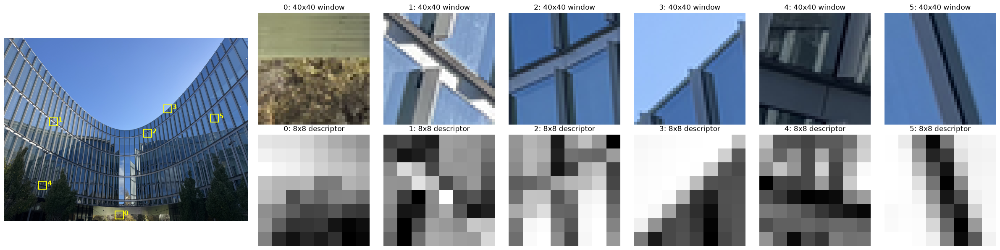

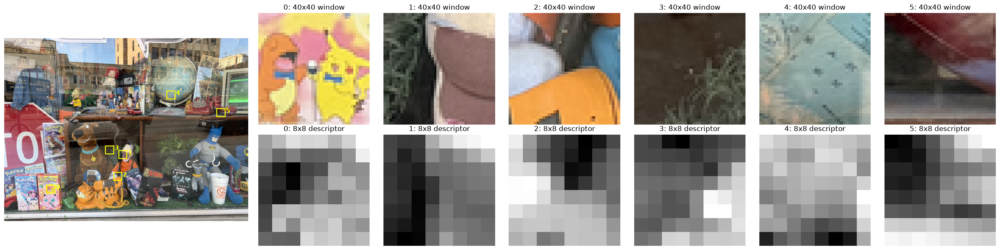

In [12]:
features = {}  # name -> [(points, descriptors) per image]
for name, ims in images.items():
    features[name] = [extract_descriptors(im, pts) for im, pts in zip(ims, anms_pts[name])]
    for i, (pts, desc) in enumerate(features[name]):
        print(f"{name} image {i}: {len(pts)} descriptors {desc.shape}, "
              f"mean {desc.mean(1).mean():+.1e}, std {desc.std(1).mean():.3f}")

rng = np.random.default_rng(0)
for name in ["mosaic1", "mosaic2"]:
    ref = len(images[name]) // 2
    pts, desc = features[name][ref]
    idx = rng.choice(len(pts), 6, replace=False)
    show_descriptors(images[name][ref], pts, desc, idx, save=f"{name}_descriptors.jpg")

## B.3 Feature Matching

Each descriptor in image *i* is compared with every descriptor in the reference image using the squared
distance (SSD). Following Lowe and Figure 6b of the paper, a match is kept only if the ratio
$e_{1\text{-NN}} / e_{2\text{-NN}}$ (best SSD divided by second-best SSD) is below 0.5. As an extra filter, I keep a match only if it is also the reference
feature's nearest neighbour (a mutual nearest neighbour).

In [13]:
RATIO = 0.5


def nn_ratios(desc1, desc2):
    d = dist2(desc1, desc2)  # squared SSD, N1 x N2
    nn = np.argsort(d, axis=1)[:, :2]
    rows = np.arange(len(d))
    return nn[:, 0], d[rows, nn[:, 0]] / np.maximum(d[rows, nn[:, 1]], 1e-12), d


def match_features(desc1, desc2, ratio=RATIO, mutual=True):
    nn, r, d = nn_ratios(desc1, desc2)
    keep = r < ratio
    if mutual:  # the reference feature's nearest neighbour must point back
        keep &= d.argmin(0)[nn] == np.arange(len(nn))
    return np.flatnonzero(keep), nn[keep]


def plot_matches(im1, im2, p1, p2, title="", save=None):
    h = max(im1.shape[0], im2.shape[0])
    pad = lambda im: np.pad(im, ((0, h - im.shape[0]), (0, 0), (0, 0)))
    canvas, off = np.hstack([pad(im1), pad(im2)]), im1.shape[1]
    fig, ax = plt.subplots(figsize=(16, 16 * h / canvas.shape[1] + 0.6))
    ax.imshow(canvas); ax.axis("off"); ax.set_title(title)
    colors = plt.cm.hsv(np.random.default_rng(0).random(len(p1)))
    for (x1, y1), (x2, y2), c in zip(p1, p2, colors):
        ax.plot([x1, x2 + off], [y1, y2], "-", color=c, lw=0.8)
    ax.scatter(p1[:, 0], p1[:, 1], s=14, c=colors)
    ax.scatter(p2[:, 0] + off, p2[:, 1], s=14, c=colors)
    plt.tight_layout()
    if save: fig.savefig(OUT / save, dpi=150, bbox_inches="tight")
    plt.show()

mosaic1 image 0 -> 1: 10 matches from 500 features


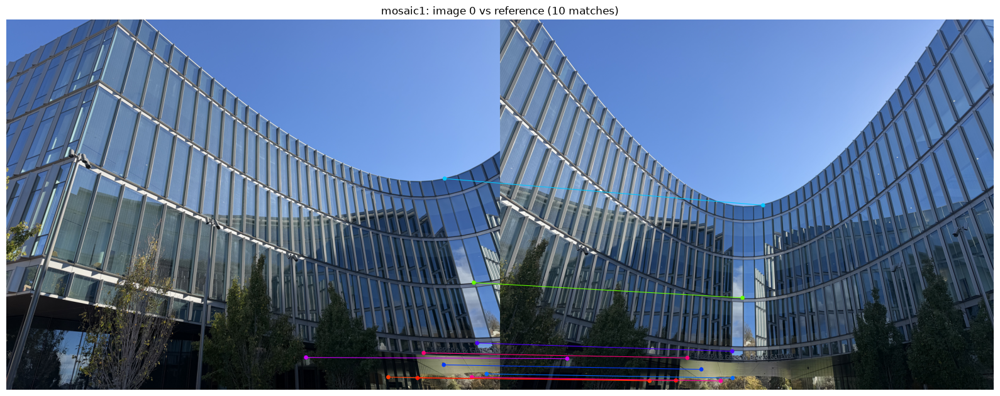

mosaic1 image 2 -> 1: 37 matches from 500 features


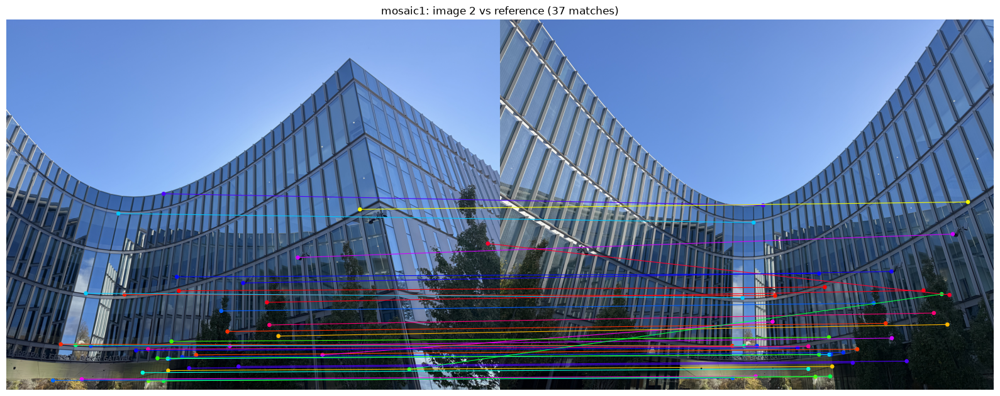

mosaic2 image 0 -> 1: 111 matches from 500 features


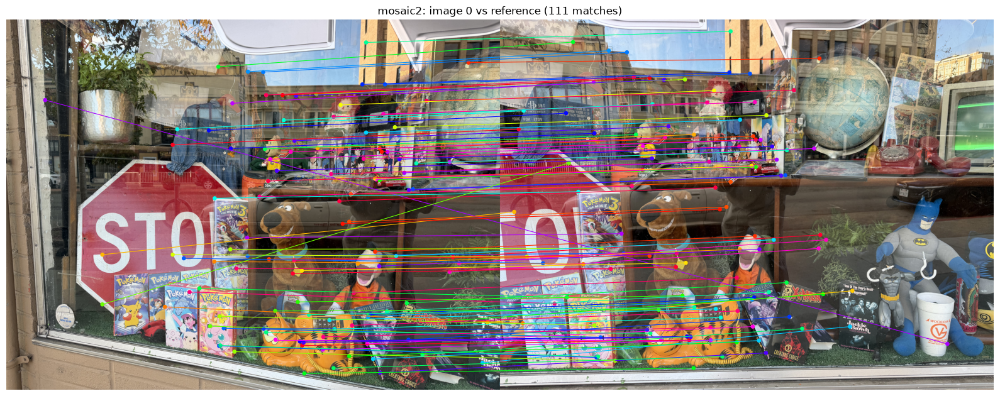

mosaic2 image 2 -> 1: 112 matches from 500 features


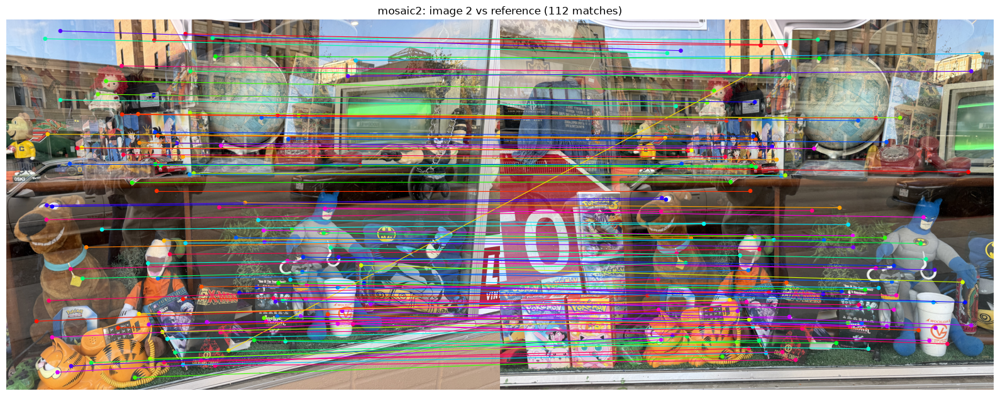

mosaic3 image 0 -> 1: 117 matches from 500 features


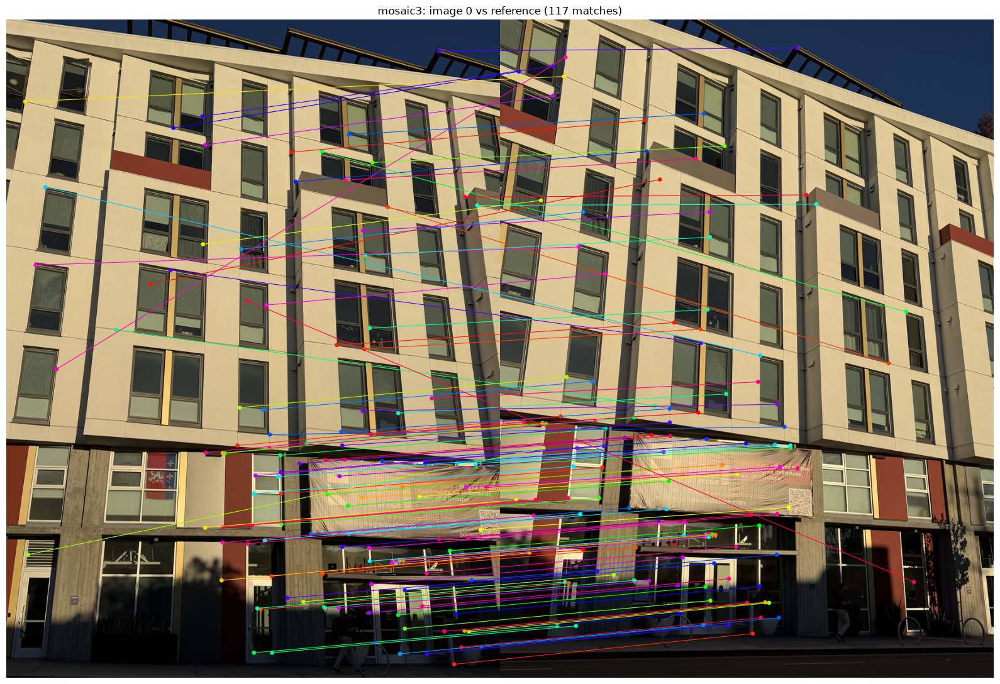

In [14]:
matches = {}  # (name, i) -> (pts in image i, pts in reference image)
for name, ims in images.items():
    ref = len(ims) // 2
    p_ref, d_ref = features[name][ref]
    for i in range(len(ims)):
        if i == ref: continue
        p_i, d_i = features[name][i]
        i1, i2 = match_features(d_i, d_ref)
        matches[name, i] = (p_i[i1], p_ref[i2])
        print(f"{name} image {i} -> {ref}: {len(i1)} matches from {len(p_i)} features")
        plot_matches(ims[i], ims[ref], *matches[name, i],
                     f"{name}: image {i} vs reference ({len(i1)} matches)", save=f"{name}_matches_{i}.jpg")

In [15]:
def manual_H(name, i, ref):
    d = json.loads((POINTS / f"{name}_{i}_to_{ref}.json").read_text())
    return computeH(np.array(d["im1"]), np.array(d["im2"]))


def ratio_stats(name, i, ref, tol=10):
    (p_i, d_i), (p_ref, d_ref) = features[name][i], features[name][ref]
    nn, r, _ = nn_ratios(d_i, d_ref)
    err = np.linalg.norm(apply_H(manual_H(name, i, ref), p_i) - p_ref[nn], axis=1)
    return r, err < tol  # 1-NN ratio, and whether that 1-NN is geometrically correct

mosaic1 image 0: 90% of 10 matches agree with the manual H
mosaic1 image 2: 86% of 37 matches agree with the manual H
mosaic2 image 0: 93% of 111 matches agree with the manual H
mosaic2 image 2: 93% of 112 matches agree with the manual H
mosaic3 image 0: 86% of 117 matches agree with the manual H


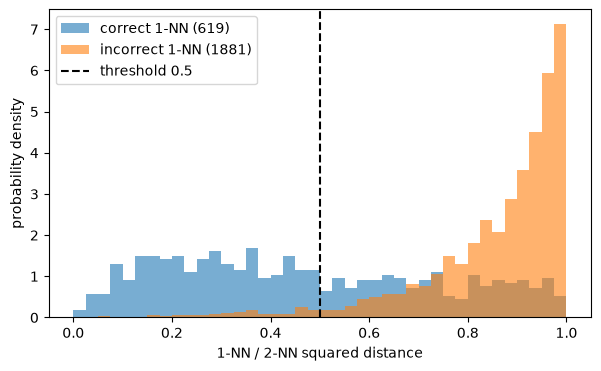

In [16]:
r_all, ok_all = [], []
for name, ims in images.items():
    ref = len(ims) // 2
    for i in range(len(ims)):
        if i == ref: continue
        r, ok = ratio_stats(name, i, ref)
        r_all.append(r); ok_all.append(ok)
        p_i, p_ref = matches[name, i]
        err = np.linalg.norm(apply_H(manual_H(name, i, ref), p_i) - p_ref, axis=1)
        print(f"{name} image {i}: {np.mean(err < 10):.0%} of {len(err)} matches agree with the manual H")
r_all, ok_all = np.concatenate(r_all), np.concatenate(ok_all)

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 1, 41)
ax.hist(r_all[ok_all], bins, density=True, alpha=0.6, label=f"correct 1-NN ({ok_all.sum()})")
ax.hist(r_all[~ok_all], bins, density=True, alpha=0.6, label=f"incorrect 1-NN ({(~ok_all).sum()})")
ax.axvline(RATIO, color="k", ls="--", label=f"threshold {RATIO}")
ax.set_xlabel("1-NN / 2-NN squared distance"); ax.set_ylabel("probability density"); ax.legend()
fig.savefig(OUT / "ratio_hist.jpg", dpi=150, bbox_inches="tight"); plt.show()

## B.4 RANSAC for Robust Homography

In [17]:
def ransac_homography(p1, p2, n_iter=5000, eps=3.0, seed=0):
    rng = np.random.default_rng(seed)
    best = np.zeros(len(p1), bool)
    with np.errstate(divide="ignore", invalid="ignore"):  # degenerate 4-point samples
        for _ in range(n_iter):
            s = rng.choice(len(p1), 4, replace=False)
            H = computeH(p1[s], p2[s])
            inl = np.linalg.norm(apply_H(H, p1) - p2, axis=1) < eps
            if inl.sum() > best.sum():
                best = inl
    return computeH(p1[best], p2[best]), best


def clicked_error(H, name, i, ref):
    d = json.loads((POINTS / f"{name}_{i}_to_{ref}.json").read_text())
    return np.linalg.norm(apply_H(H, np.array(d["im1"])) - np.array(d["im2"]), axis=1)

mosaic1 image 0: 9/10 inliers, inlier residual 0.72px | clicked points: manual H 1.6px, auto H 8.0px


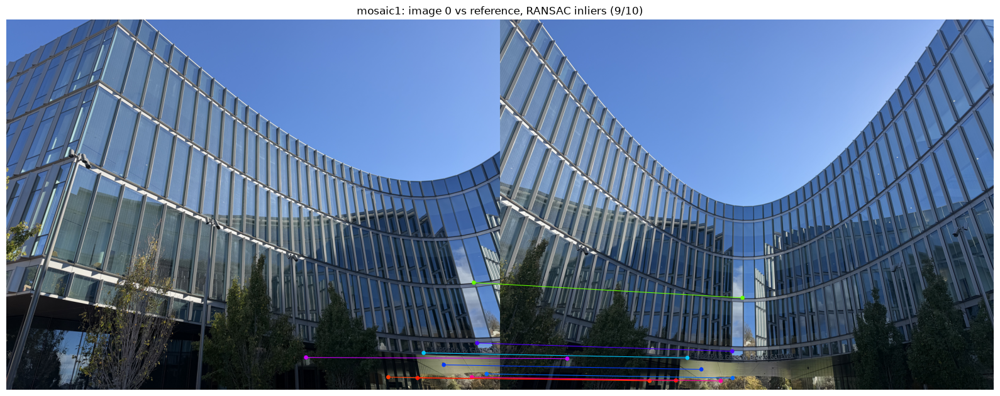

mosaic1 image 2: 31/37 inliers, inlier residual 0.99px | clicked points: manual H 4.5px, auto H 5.0px


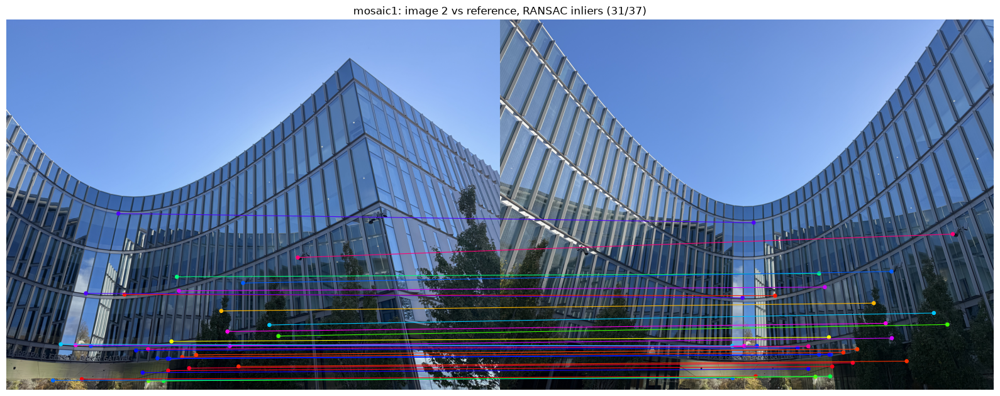

mosaic2 image 0: 80/111 inliers, inlier residual 1.31px | clicked points: manual H 3.6px, auto H 4.7px


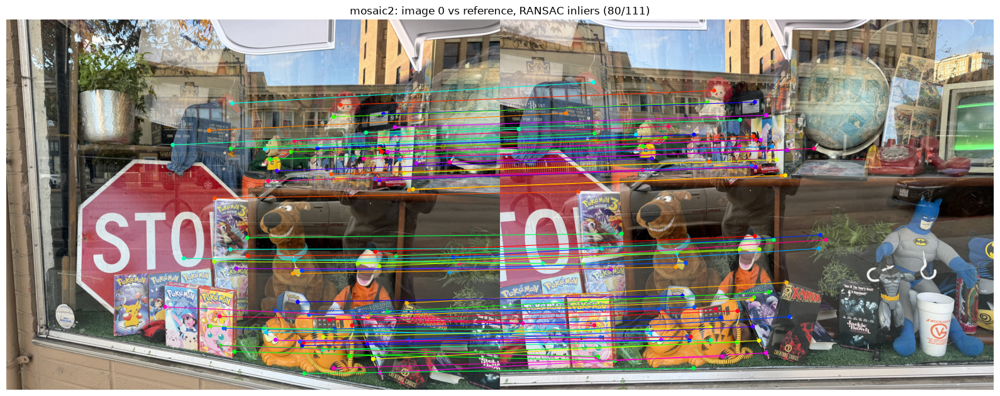

mosaic2 image 2: 89/112 inliers, inlier residual 1.44px | clicked points: manual H 2.7px, auto H 7.7px


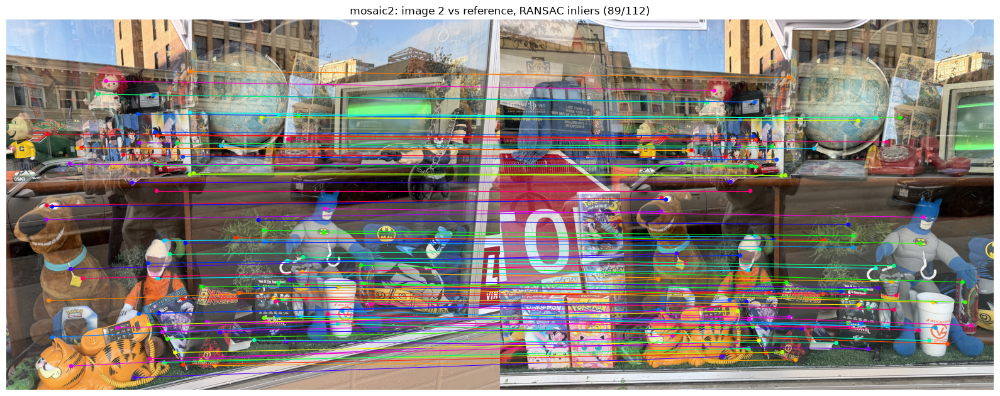

mosaic3 image 0: 95/117 inliers, inlier residual 1.46px | clicked points: manual H 4.1px, auto H 4.7px


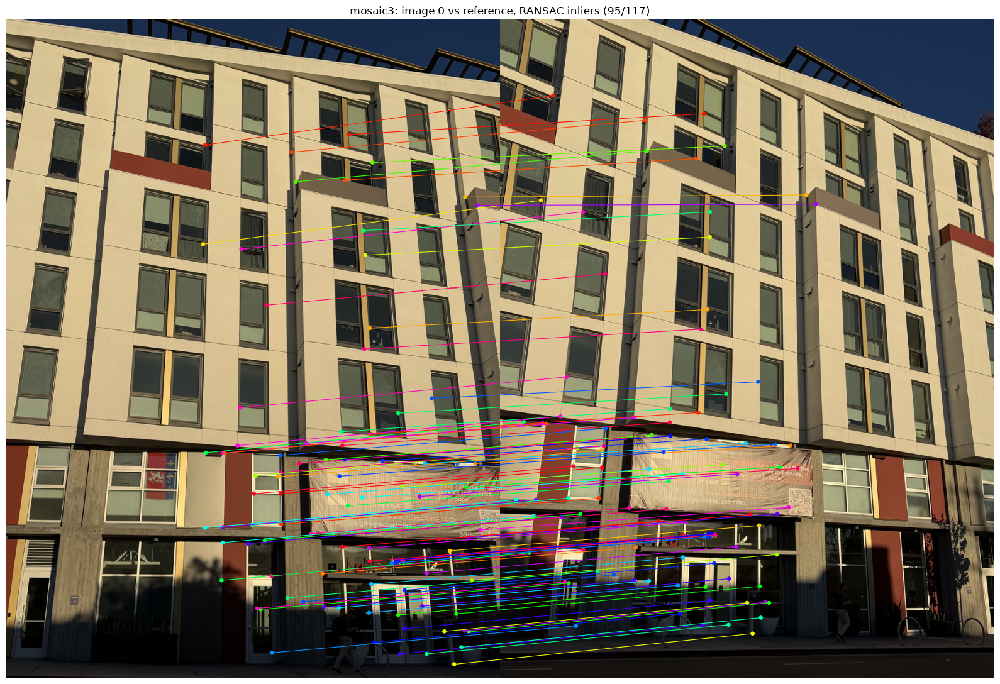

In [18]:
auto_Hs = {}  # name -> list of H (image i -> reference)
for name, ims in images.items():
    ref = len(ims) // 2
    auto_Hs[name] = []
    for i in range(len(ims)):
        if i == ref:
            auto_Hs[name].append(np.eye(3)); continue
        p_i, p_ref = matches[name, i]
        H, inl = ransac_homography(p_i, p_ref)
        auto_Hs[name].append(H)
        res = np.linalg.norm(apply_H(H, p_i[inl]) - p_ref[inl], axis=1)
        e_auto, e_man = clicked_error(H, name, i, ref), clicked_error(manual_H(name, i, ref), name, i, ref)
        print(f"{name} image {i}: {inl.sum()}/{len(inl)} inliers, inlier residual {res.mean():.2f}px | "
              f"clicked points: manual H {e_man.mean():.1f}px, auto H {e_auto.mean():.1f}px")
        plot_matches(ims[i], ims[ref], p_i[inl], p_ref[inl],
                     f"{name}: image {i} vs reference, RANSAC inliers ({inl.sum()}/{len(inl)})",
                     save=f"{name}_inliers_{i}.jpg")

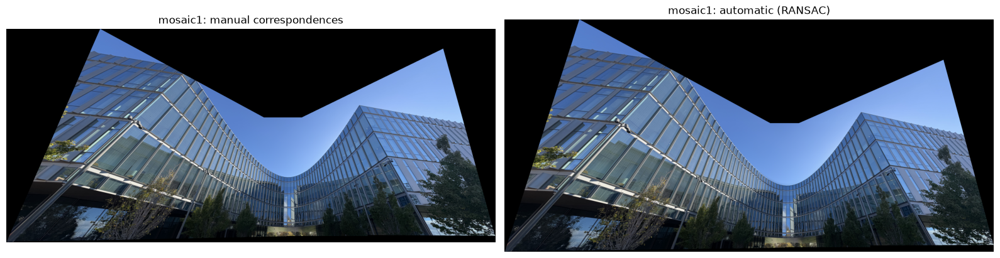

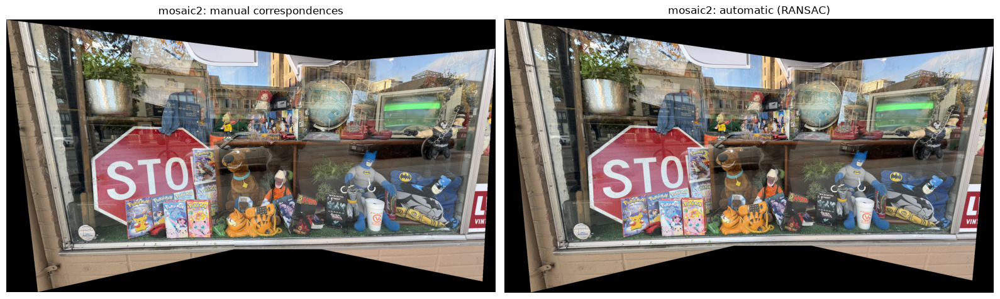

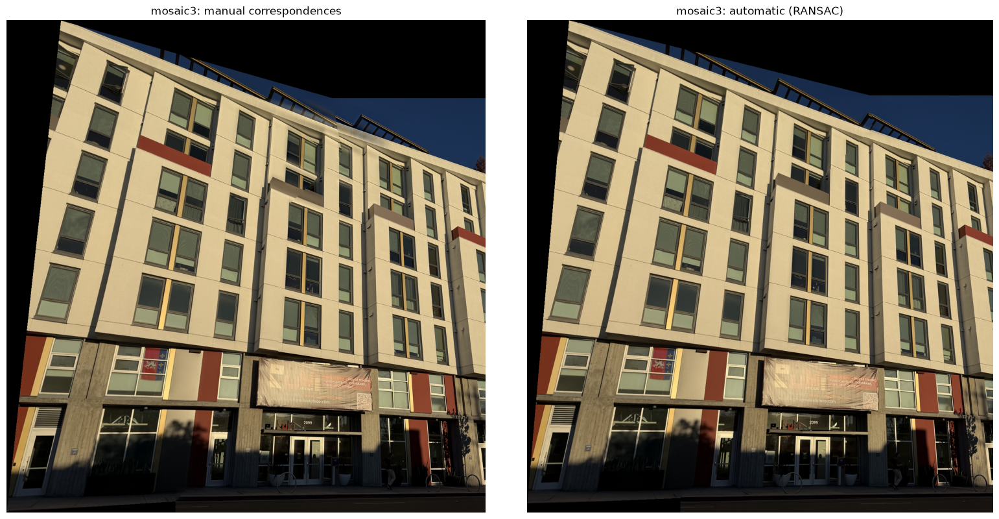

In [19]:
auto_mosaics = {}
for name, ims in images.items():
    ref = len(ims) // 2
    manual_Hs = [np.eye(3) if i == ref else manual_H(name, i, ref) for i in range(len(ims))]
    manual = make_mosaic(ims, manual_Hs)[0]
    auto = make_mosaic(ims, auto_Hs[name])[0]
    auto_mosaics[name] = auto
    save_image(auto, f"{name}_auto.jpg")
    show([manual, auto], [f"{name}: manual correspondences", f"{name}: automatic (RANSAC)"],
         size=8, save=f"{name}_manual_vs_auto.jpg")

## B.5 Bells & Whistles: Rotation-Invariant Descriptors

In [27]:
def orientations(im, pts, sigma_o=4.5):
    gy, gx = np.gradient(gaussian_filter(to_gray(im), sigma_o))
    x, y = np.round(pts).astype(int).T
    return np.arctan2(gy[y, x], gx[y, x])


def extract_oriented_descriptors(im, pts, theta, window=40, size=8, sigma=2):
    g = gaussian_filter(to_gray(im), sigma)
    offs = (np.arange(size) - (size - 1) / 2) * (window / size)
    dx, dy = [o.ravel() for o in np.meshgrid(offs, offs)]
    c, s = np.cos(theta)[:, None], np.sin(theta)[:, None]
    sx = pts[:, 0, None] + c * dx - s * dy  # rotate the sample grid by theta
    sy = pts[:, 1, None] + s * dx + c * dy
    desc, valid = bilinear_sample(g, sx, sy)
    keep = valid.all(1)  # a rotated window can reach ~28px out, so some edge corners drop
    desc = desc[keep]
    desc = (desc - desc.mean(1, keepdims=True)) / (desc.std(1, keepdims=True) + 1e-8)
    return pts[keep], desc, theta[keep]


def plot_oriented(ax, im, pts, theta, title="", window=40):
    ax.imshow(im); ax.axis("off"); ax.set_title(title)
    h = window / 2
    box = np.array([[-h, -h], [h, -h], [h, h], [-h, h], [-h, -h]])
    for (x, y), t in zip(pts, theta):
        R = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
        q = box @ R.T + [x, y]
        ax.plot(q[:, 0], q[:, 1], "y-", lw=0.7)
        ax.plot([x, x + h * np.cos(t)], [y, y + h * np.sin(t)], "r-", lw=0.9)  # orientation


492 oriented descriptors (492, 64)


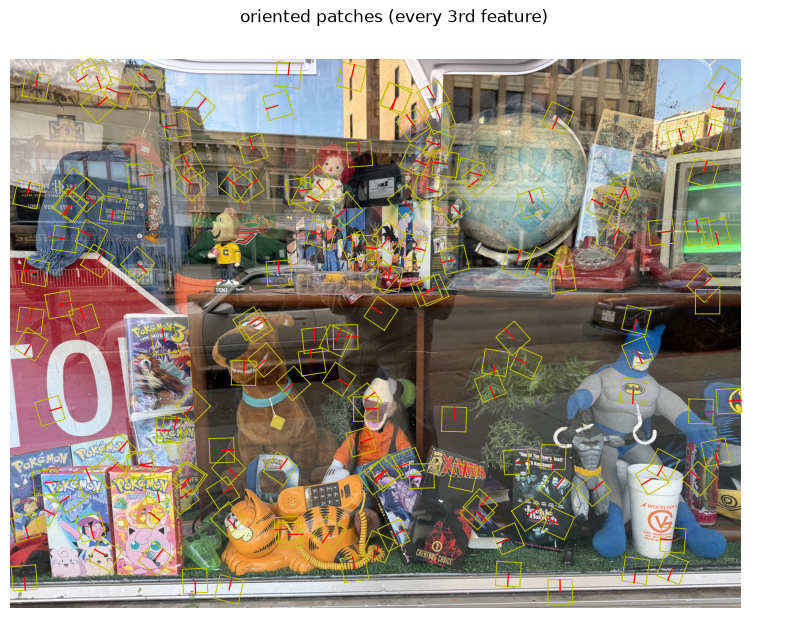

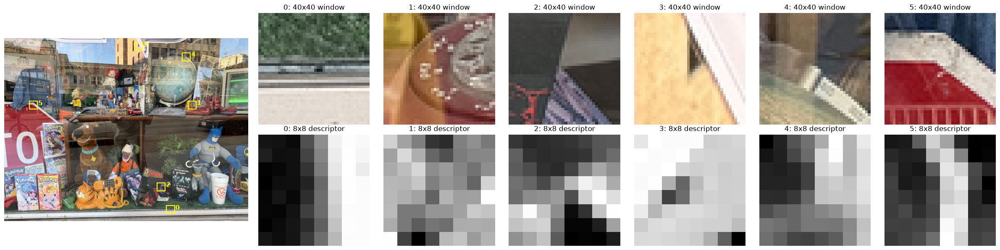

In [28]:
im = images["mosaic2"][1]
pts, f = harris_corners(im)
pts = anms(pts, f)[0]
o_pts, o_desc, o_theta = extract_oriented_descriptors(im, pts, orientations(im, pts))
print(f"{len(o_pts)} oriented descriptors {o_desc.shape}")

fig, ax = plt.subplots(figsize=(10, 7.5))
plot_oriented(ax, im, o_pts[::3], o_theta[::3], "oriented patches (every 3rd feature)")
fig.savefig(OUT / "oriented_features.jpg", dpi=150, bbox_inches="tight"); plt.show()
show_descriptors(im, o_pts, o_desc, np.random.default_rng(0).choice(len(o_pts), 6, replace=False),
                 save="oriented_descriptors.jpg")

In [29]:
def rotate_image(im, deg):
    h, w = im.shape[:2]
    t = np.deg2rad(deg)
    T = np.array([[1, 0, -(w - 1) / 2], [0, 1, -(h - 1) / 2], [0, 0, 1]])
    R = np.array([[np.cos(t), -np.sin(t), 0], [np.sin(t), np.cos(t), 0], [0, 0, 1]])
    H = np.linalg.inv(T) @ R @ T  # rotate about the image center
    out, alpha, (x0, y0) = warpImageBilinear(im, H)
    return out, alpha, np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]]) @ H  # true H: im -> out


def detect_and_describe(im, oriented=True):
    pts, f = harris_corners(im)
    pts = anms(pts, f)[0]
    if not oriented:
        pts, desc = extract_descriptors(im, pts)
        return pts, desc, np.zeros(len(pts))
    return extract_oriented_descriptors(im, pts, orientations(im, pts))

   0 deg: axis-aligned 500 correct, oriented 492 correct
  15 deg: axis-aligned  44 correct, oriented 262 correct
  30 deg: axis-aligned   1 correct, oriented 296 correct
  45 deg: axis-aligned   0 correct, oriented 328 correct
  60 deg: axis-aligned   0 correct, oriented 296 correct
  90 deg: axis-aligned   0 correct, oriented 490 correct
 135 deg: axis-aligned   0 correct, oriented 328 correct
 180 deg: axis-aligned   0 correct, oriented 488 correct


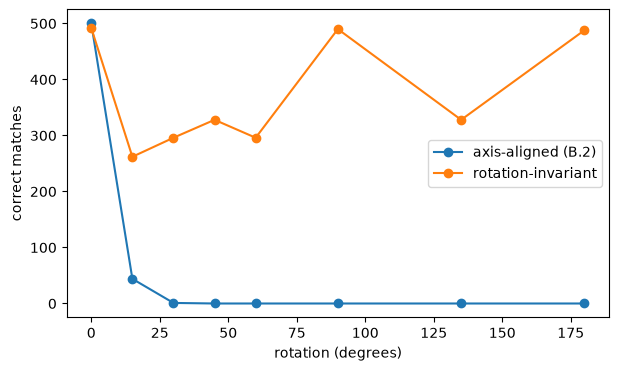

In [30]:
angles = [0, 15, 30, 45, 60, 90, 135, 180]
base = {o: detect_and_describe(im, o) for o in (False, True)}
correct = {False: [], True: []}
for deg in angles:
    rot, _, H_true = rotate_image(im, deg)
    for o in (False, True):
        p1, d1, _ = base[o]
        p2, d2, _ = detect_and_describe(rot, o)
        i1, i2 = match_features(d1, d2)
        ok = np.linalg.norm(apply_H(H_true, p1[i1]) - p2[i2], axis=1) < 5
        correct[o].append(ok.sum())
    print(f"{deg:4d} deg: axis-aligned {correct[False][-1]:3d} correct, oriented {correct[True][-1]:3d} correct")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(angles, correct[False], "o-", label="axis-aligned (B.2)")
ax.plot(angles, correct[True], "o-", label="rotation-invariant")
ax.set_xlabel("rotation (degrees)"); ax.set_ylabel("correct matches"); ax.legend()
fig.savefig(OUT / "rotation_sweep.jpg", dpi=150, bbox_inches="tight"); plt.show()

axis-aligned: 1 matches


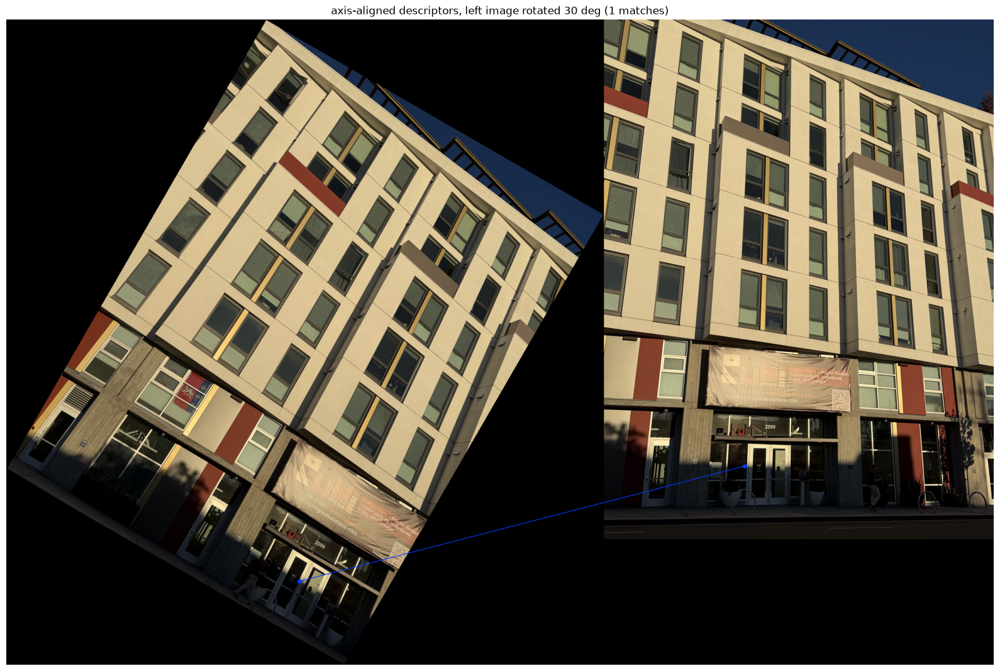

oriented: 111 matches


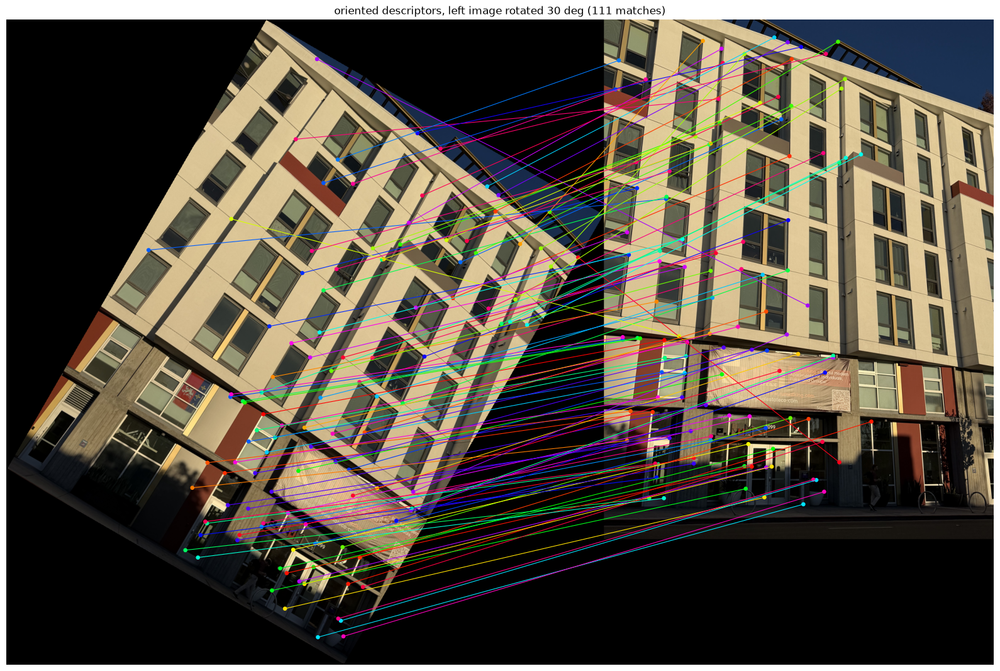

oriented RANSAC: 87/111 inliers


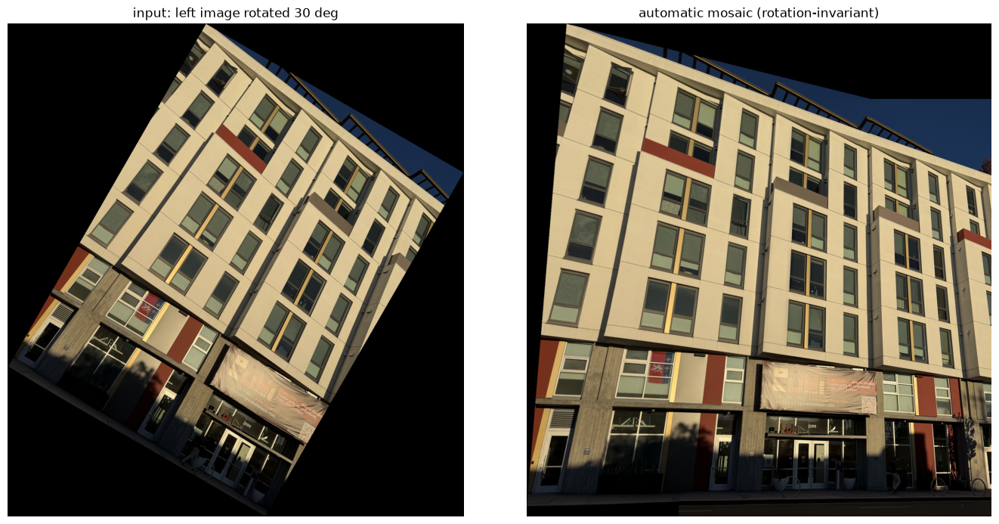

In [31]:
from scipy.ndimage import distance_transform_edt

ims = images["mosaic3"]
rot, alpha, _ = rotate_image(ims[0], 30)
for o, label in ((False, "axis-aligned"), (True, "oriented")):
    p1, d1, _ = detect_and_describe(rot, o)
    p2, d2, _ = detect_and_describe(ims[1], o)
    i1, i2 = match_features(d1, d2)
    print(f"{label}: {len(i1)} matches")
    plot_matches(rot, ims[1], p1[i1], p2[i2], f"{label} descriptors, left image rotated 30 deg ({len(i1)} matches)",
                 save=f"rotated_matches_{label}.jpg")
H, inl = ransac_homography(p1[i1], p2[i2])  # oriented matches from the last loop iteration
print(f"oriented RANSAC: {inl.sum()}/{len(inl)} inliers")

w_rot = distance_transform_edt(alpha > 0.5); w_rot /= w_rot.max()  # feather only the valid region
mos = make_mosaic([rot, ims[1]], [H, np.eye(3)], [w_rot, feather_alpha(*ims[1].shape[:2])])[0]
ys, xs = np.nonzero(mos.sum(2))
mos = mos[ys.min():ys.max() + 1, xs.min():xs.max() + 1]  # crop the empty canvas
show([rot, mos], ["input: left image rotated 30 deg", "automatic mosaic (rotation-invariant)"],
     size=7, save="rotated_mosaic.jpg")